<a href="https://colab.research.google.com/github/PierreCr/Digital-Pathology/blob/main/Mini_project_in_Computational_Pathology_Part_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini-project in Computational Pathology - Part 2.
# Pierre Cordier, DVM, PhD, Dipl.ECVP.
# 11/10/2026.


In [4]:
#19.0. Now introduce AI.
from google.colab import drive
drive.mount("/content/drive/")

Mounted at /content/drive/


In [5]:
#19.1. Now introduce AI.
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")


# Load pretrained image encoder: ResNet-18
from torchvision.models import resnet18, ResNet18_Weights

# Load pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Remove the final 1000-class classification layer
model.fc = torch.nn.Identity()

# Prepare for inference, not training
model.eval()

# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# Use the preprocessing designed for these weights
preprocess = weights.transforms()

print("Device:", device)
print("Model ready")

PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
Device: CPU
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 148MB/s]

Device: cpu
Model ready


Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).
Embedding shape: (1, 512)
First 10 values: [4.095182   0.41849878 0.5878881  1.8071091  1.0889583  1.3097417
 0.16083336 1.1377448  3.5635405  1.1332175 ]


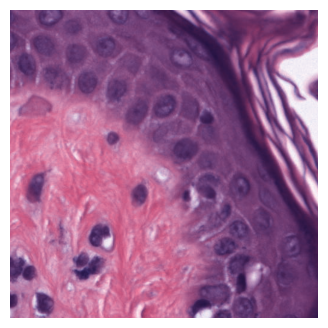

In [6]:
#19.2. Run model on 1 patch.
from google.colab import drive
drive.mount("/content/drive/")

# Load 1 image
patch = Image.open("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/CMU-1_patch_53_normed.png").convert("RGB")
plt.figure(figsize=(4, 4))
plt.imshow(patch)
plt.axis("off");

# Convert the image to a normalized tensor
image_tensor = preprocess(patch)

# Add a batch dimension: (3, 224, 224) -> (1, 3, 224, 224)
batch = image_tensor.unsqueeze(0).to(device)

with torch.inference_mode():
    embedding = model(batch)

embedding = embedding.cpu().numpy()

print("Embedding shape:", embedding.shape)
print("First 10 values:", embedding[0, :10])

In [8]:
#19.3. Run model on all patches.
patch_dir = Path("/content/drive/MyDrive/WSI_CMU-1/normedMacenko_patches512x512/")

image_paths = sorted([
  p for p in patch_dir.iterdir()
  if p.suffix.lower() in {".png", ".jpg", ".jpeg"}])

print("Number of patches:", len(image_paths))

if len(image_paths) == 0:
  raise ValueError("No images found. Check patch_dir.")


#
from torch.utils.data import Dataset, DataLoader

class PatchDataset(Dataset):
  def __init__(self, paths, transform):
    self.paths = paths
    self.transform = transform

  def __len__(self):
    return len(self.paths)

  def __getitem__(self, index):
    path = self.paths[index]

    with Image.open(path) as image:
      image = image.convert("RGB")
      tensor = self.transform(image)
    return tensor, str(path)

dataset = PatchDataset(image_paths, preprocess)

loader = DataLoader(
      dataset,
      batch_size=32,
      shuffle=False,
      num_workers=0)

all_embeddings = []
all_paths = []

with torch.inference_mode():
  for images, paths in loader:
    images = images.to(device)
    features = model(images)
    all_embeddings.append(features.cpu().numpy())
    all_paths.extend(paths)

embeddings = np.concatenate(all_embeddings, axis=0)
print("Embedding matrix:", embeddings.shape)

Embedding matrix: (96, 512)


In [9]:
#19.4. Run model on all patches.
output_dir = Path("/content/drive/MyDrive/WSI_CMU-1/Metadata/")
output_dir.mkdir(parents=True, exist_ok=True)

np.save(output_dir / "embeddings.npy", embeddings)
metadata = pd.DataFrame({
  "patch_path": all_paths,
  "embedding_row": np.arange(len(all_paths))})

metadata.to_csv(output_dir / "patch_metadata.csv", index=False)

print("Saved embeddings and metadata.")

Saved embeddings and metadata.


In [ ]:
#20. Understand embeddings before classification.


# --
#Q45. What does one row represent?
#Q46. What does one column represent?
#Q47. Are the 768 features individually interpretable as "nucleus", "lymphocyte", "collagen", etc.? Be careful here.

PCA shape: (96, 2)
Variance explained by two components: 0.308


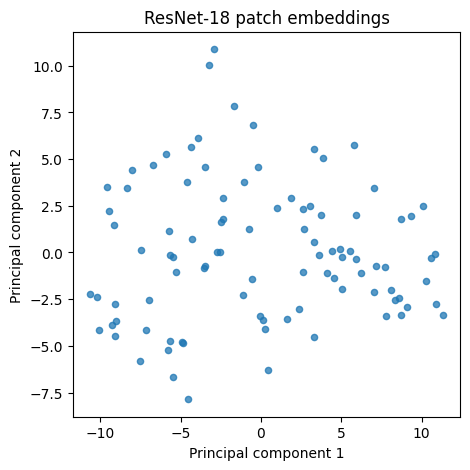

In [12]:
#21. Visualize the embeddings with PCA.
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Reduce 512 features to 2 dimensions
pca = PCA(n_components=2)
embedding_2d = pca.fit_transform(embeddings)

print("PCA shape:", embedding_2d.shape)
print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(5, 5))
plt.scatter(
    embedding_2d[:, 0],
    embedding_2d[:, 1],
    s=20,
    alpha=0.75)

plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("ResNet-18 patch embeddings")
plt.show()